In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the six Maven Fuzzy Factory datasets
sessions = pd.read_csv('website_sessions.csv')
pageviews = pd.read_csv('website_pageviews.csv')
orders = pd.read_csv('orders_mav.csv')
order_items = pd.read_csv('order_items.csv')
refunds = pd.read_csv('order_item_refunds.csv')
products = pd.read_csv('products.csv')

datasets = {
    'website_sessions': sessions,
    'website_pageviews': pageviews,
    'orders_mav': orders,
    'order_items': order_items,
    'order_item_refunds': refunds,
    'products': products
}

# Inspect shapes, duplicates, and missing values
for name, df in datasets.items():
    print(f"=== {name.upper()} ===")
    print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
    print(f"Exact Duplicate Rows: {df.duplicated().sum()}")
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    if not missing.empty:
        print("Missing Values:\n", missing)
    else:
        print("Missing Values: None")
    print("-" * 40)

=== WEBSITE_SESSIONS ===
Shape: 472871 rows, 9 columns
Exact Duplicate Rows: 0
Missing Values:
 utm_source      83328
utm_campaign    83328
utm_content     83328
http_referer    39917
dtype: int64
----------------------------------------
=== WEBSITE_PAGEVIEWS ===
Shape: 1048575 rows, 4 columns
Exact Duplicate Rows: 0
Missing Values: None
----------------------------------------
=== ORDERS_MAV ===
Shape: 32313 rows, 8 columns
Exact Duplicate Rows: 0
Missing Values: None
----------------------------------------
=== ORDER_ITEMS ===
Shape: 40025 rows, 7 columns
Exact Duplicate Rows: 0
Missing Values: None
----------------------------------------
=== ORDER_ITEM_REFUNDS ===
Shape: 1731 rows, 5 columns
Exact Duplicate Rows: 0
Missing Values: None
----------------------------------------
=== PRODUCTS ===
Shape: 4 rows, 3 columns
Exact Duplicate Rows: 0
Missing Values: None
----------------------------------------


In [12]:
for name, df in datasets.items():
    if 'created_at' in df.columns:
        df['created_at'] = pd.to_datetime(df['created_at'])
         
#Extract useful time features on sessions and orders
sessions['year_month'] = sessions['created_at'].dt.to_period("M")
orders['year_month'] = orders['created_at'].dt.to_period('M')

def classify_channel(row):
    if pd.notnull(row['utm_source']):
        return f"{row['utm_source']} ({row['utm_campaign']})"
    elif pd.notnull(row['http_referer']):
        return 'organic_search'
    else:
        return 'direct_type_in'

sessions['traffic_channel'] = sessions.apply(classify_channel, axis=1)
sessions['utm_source_clean'] = sessions['utm_source'].where(
    sessions['utm_source'].notna(),
    np.where(sessions['http_referer'].notnull(), 'organic_search', 'direct')
)

print("Data cleaning complete!")
print("\nTraffic Sources Breakdown:")
print(sessions['utm_source_clean'].value_counts())


Data cleaning complete!

Traffic Sources Breakdown:
utm_source_clean
gsearch           316035
bsearch            62823
organic_search     43411
direct             39917
socialbook         10685
Name: count, dtype: int64


Task 2: Exploratory Data Analysis (Questions 1–8)

In [13]:
import pandas as pd
import numpy as np

# Configure Pandas to display all columns cleanly without wrapping or truncating
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)

# Verify exact start and end dates of the dataset
print(f"Sessions Date Range: {sessions['created_at'].min()} to {sessions['created_at'].max()}")
print(f"Orders Date Range:   {orders['created_at'].min()} to {orders['created_at'].max()}")

Sessions Date Range: 2012-03-19 08:04:00 to 2015-03-19 07:59:00
Orders Date Range:   2012-03-19 10:42:00 to 2015-03-19 05:38:00


In [14]:
print("=== Q1: MONTHLY REVENUE, COGS & NET MARGIN ===")
monthly_rev = orders.groupby('year_month').agg(
    orders_count=('order_id', 'count'),
    total_revenue=('price_usd', 'sum'),
    total_cogs=('cogs_usd', 'sum')
)
monthly_rev['net_margin'] = monthly_rev['total_revenue'] - monthly_rev['total_cogs']
monthly_rev['aov'] = round(monthly_rev['total_revenue'] / monthly_rev['orders_count'], 2)

print(monthly_rev)

=== Q1: MONTHLY REVENUE, COGS & NET MARGIN ===
            orders_count  total_revenue  total_cogs  net_margin    aov
year_month                                                            
2012-03               60        2999.40     1169.40      1830.0  49.99
2012-04               99        4949.01     1929.51      3019.5  49.99
2012-05              108        5398.92     2104.92      3294.0  49.99
2012-06              140        6998.60     2728.60      4270.0  49.99
2012-07              169        8448.31     3293.81      5154.5  49.99
2012-08              228       11397.72     4443.72      6954.0  49.99
2012-09              287       14347.13     5593.63      8753.5  49.99
2012-10              371       18546.29     7230.79     11315.5  49.99
2012-11              618       30893.82    12044.82     18849.0  49.99
2012-12              506       25294.94     9861.94     15433.0  49.99
2013-01              390       19966.10     7742.10     12224.0  51.20
2013-02              498      

In [15]:
# Merge product names onto order_items
items_with_prod = order_items.merge(products, on='product_id', how='left')

print("=== Q2: PRODUCT SALES & REVENUE ===")
prod_perf = items_with_prod.groupby('product_name').agg(
    units_sold=('order_item_id', 'count'),
    total_revenue=('price_usd', 'sum'),
    total_cogs=('cogs_usd', 'sum')
).sort_values(by='total_revenue', ascending=False)
prod_perf['net_margin'] = prod_perf['total_revenue'] - prod_perf['total_cogs']
prod_perf['revenue_share_%'] = round((prod_perf['total_revenue'] / prod_perf['total_revenue'].sum()) * 100, 2)
print(prod_perf, "\n")

print("=== Q3: CUSTOMER PURCHASING PATTERNS ===")
items_dist = orders['items_purchased'].value_counts().to_frame(name='order_count')
items_dist['share_%'] = round((items_dist['order_count'] / len(orders)) * 100, 2)
print(items_dist)
print(f"\nAverage Order Value (AOV): ${orders['price_usd'].mean():.2f}")
print(f"Median Order Value:        ${orders['price_usd'].median():.2f}")

=== Q2: PRODUCT SALES & REVENUE ===
                            units_sold  total_revenue  total_cogs  net_margin  revenue_share_%
product_name                                                                                  
The Original Mr. Fuzzy           24226     1211057.74   472164.74    738893.0            62.47
The Forever Love Bear             5796      347702.04   130352.04    217350.0            17.94
The Birthday Sugar Panda          4985      229260.15    72232.65    157027.5            11.83
The Hudson River Mini bear        5018      150489.82    47620.82    102869.0             7.76 

=== Q3: CUSTOMER PURCHASING PATTERNS ===
                 order_count  share_%
items_purchased                      
1                      24601    76.13
2                       7712    23.87

Average Order Value (AOV): $59.99
Median Order Value:        $49.99


In [17]:
# Merge sessions with orders to flag converted sessions
sess_orders = sessions.merge(
    orders[['website_session_id', 'order_id', 'price_usd']], 
    on='website_session_id', 
    how='left'
)
sess_orders['converted'] = sess_orders['order_id'].notnull().astype(int)

print("=== Q4: MARKETING CHANNELS (SESSIONS & CONVERSION) ===")
channel_summary = sess_orders.groupby('utm_source_clean').agg(
    sessions=('website_session_id', 'count'),
    orders=('converted', 'sum'),
    conv_rate_pct=('converted', lambda x: round(x.mean() * 100, 2)),
    revenue=('price_usd', 'sum')
).sort_values(by='sessions', ascending=False)
channel_summary['session_share_%'] = round((channel_summary['sessions'] / len(sessions)) * 100, 2)
print(channel_summary, "\n")

print("=== Q5: MOBILE VS. DESKTOP TRAFFIC & CONVERSION ===")
device_summary = sess_orders.groupby('device_type', observed=False).agg(
    sessions=('website_session_id', 'count'),
    orders=('converted', 'sum'),
    conv_rate_pct=('converted', lambda x: round(x.mean() * 100, 2)),
    revenue=('price_usd', 'sum')
)
device_summary['session_share_%'] = round((device_summary['sessions'] / len(sessions)) * 100, 2)
print(device_summary, "\n")

print("=== Q6: OVERALL SESSION-TO-ORDER CONVERSION PROPORTION ===")
overall_conv = sess_orders['converted'].mean() * 100
print(f"Total Website Sessions: {len(sessions):,}")
print(f"Total Orders Placed:    {len(orders):,}")
print(f"Overall Conversion:     {overall_conv:.2f}%\n")

print("=== Q8: NEW VS. RETURNING SESSIONS ===")
repeat_summary = sess_orders.groupby('is_repeat_session').agg(
    sessions=('website_session_id', 'count'),
    orders=('converted', 'sum'),
    conv_rate_pct=('converted', lambda x: round(x.mean() * 100, 2)),
    revenue=('price_usd', 'sum')
)
repeat_summary.index = ['New Session (0)', 'Returning Session (1)']
print(repeat_summary)

=== Q4: MARKETING CHANNELS (SESSIONS & CONVERSION) ===
                  sessions  orders  conv_rate_pct     revenue  session_share_%
utm_source_clean                                                              
gsearch             316035   21333           6.75  1276144.89            66.83
bsearch              62823    4519           7.19   268672.50            13.29
organic_search       43411    3262           7.51   196809.19             9.18
direct               39917    2856           7.15   174623.84             8.44
socialbook           10685     343           3.21    22259.33             2.26 

=== Q5: MOBILE VS. DESKTOP TRAFFIC & CONVERSION ===
             sessions  orders  conv_rate_pct     revenue  session_share_%
device_type                                                              
desktop        327027   27805           8.50  1665757.84            69.16
mobile         145844    4508           3.09   272751.91            30.84 

=== Q6: OVERALL SESSION-TO-ORDER CONVERS

In [18]:
# Merge refund amounts onto items_with_prod
items_with_refunds = items_with_prod.merge(
    refunds[['order_item_id', 'refund_amount_usd']], 
    on='order_item_id', 
    how='left'
)

print("=== Q7: PRODUCT REFUND ACTIVITY ===")
refund_summary = items_with_refunds.groupby('product_name').agg(
    units_sold=('order_item_id', 'count'),
    refund_count=('refund_amount_usd', lambda x: x.notnull().sum()),
    refund_value_usd=('refund_amount_usd', 'sum')
)
refund_summary['refund_rate_%'] = round((refund_summary['refund_count'] / refund_summary['units_sold']) * 100, 2)

print(refund_summary.sort_values(by='refund_rate_%', ascending=False))
print(f"\nTotal Refunds: {len(refunds):,} items | Total Refunded Value: ${refunds['refund_amount_usd'].sum():,.2f}")

=== Q7: PRODUCT REFUND ACTIVITY ===
                            units_sold  refund_count  refund_value_usd  refund_rate_%
product_name                                                                         
The Birthday Sugar Panda          4985           301          13842.99           6.04
The Original Mr. Fuzzy           24226          1237          61837.63           5.11
The Forever Love Bear             5796           129           7738.71           2.23
The Hudson River Mini bear        5018            64           1919.36           1.28

Total Refunds: 1,731 items | Total Refunded Value: $85,338.69


Task 3: Statistical Analysis and Visualisation

In [19]:
import os
import scipy.stats as stats

os.makedirs('Visualisations', exist_ok=True)

print("=== 1. DESCRIPTIVE STATISTICS (ORDERS & ITEMS) ===")
print(orders[['items_purchased', 'price_usd', 'cogs_usd']].describe().round(2), "\n")

# 2. Relationship between monthly website traffic and orders
monthly_traffic = sessions.groupby('year_month').agg(sessions=('website_session_id', 'count'))
monthly_perf = monthly_traffic.join(monthly_rev[['orders_count', 'total_revenue', 'net_margin']])
monthly_perf['conv_rate_%'] = round((monthly_perf['orders_count'] / monthly_perf['sessions']) * 100, 2)

# Exclude partial final month (2015-03) for fair time-series correlation
full_months = monthly_perf.iloc[:-1]
r_val, p_val = stats.pearsonr(full_months['sessions'], full_months['orders_count'])
print("=== 2. TRAFFIC VS. ORDERS CORRELATION (FULL MONTHS) ===")
print(f"Pearson r: {r_val:.4f} | P-value: {p_val:.4e}\n")

# 3. Compare sales performance across full years (2013 vs. 2014)
orders['year'] = orders['created_at'].dt.year
yearly_comp = orders[orders['year'].isin([2013, 2014])].groupby('year').agg(
    total_orders=('order_id', 'count'),
    total_revenue=('price_usd', 'sum'),
    avg_order_value=('price_usd', 'mean')
).round(2)
print("=== 3. FULL-YEAR SALES COMPARISON (2013 VS. 2014) ===")
print(yearly_comp, "\n")

# 4. Product Sales vs. Refunds Summary
print("=== 4. PRODUCT SALES VS. REFUNDS ===")
print(refund_summary.sort_values(by='refund_rate_%', ascending=False))

=== 1. DESCRIPTIVE STATISTICS (ORDERS & ITEMS) ===
       items_purchased  price_usd  cogs_usd
count         32313.00   32313.00  32313.00
mean              1.24      59.99     22.36
std               0.43      17.81      6.24
min               1.00      29.99      9.49
25%               1.00      49.99     19.49
50%               1.00      49.99     19.49
75%               1.00      59.99     22.49
max               2.00     109.98     41.98 

=== 2. TRAFFIC VS. ORDERS CORRELATION (FULL MONTHS) ===
Pearson r: 0.9850 | P-value: 1.6424e-27

=== 3. FULL-YEAR SALES COMPARISON (2013 VS. 2014) ===
      total_orders  total_revenue  avg_order_value
year                                              
2013          7447      393247.87            52.81
2014         16860     1075612.19            63.80 

=== 4. PRODUCT SALES VS. REFUNDS ===
                            units_sold  refund_count  refund_value_usd  refund_rate_%
product_name                                                           

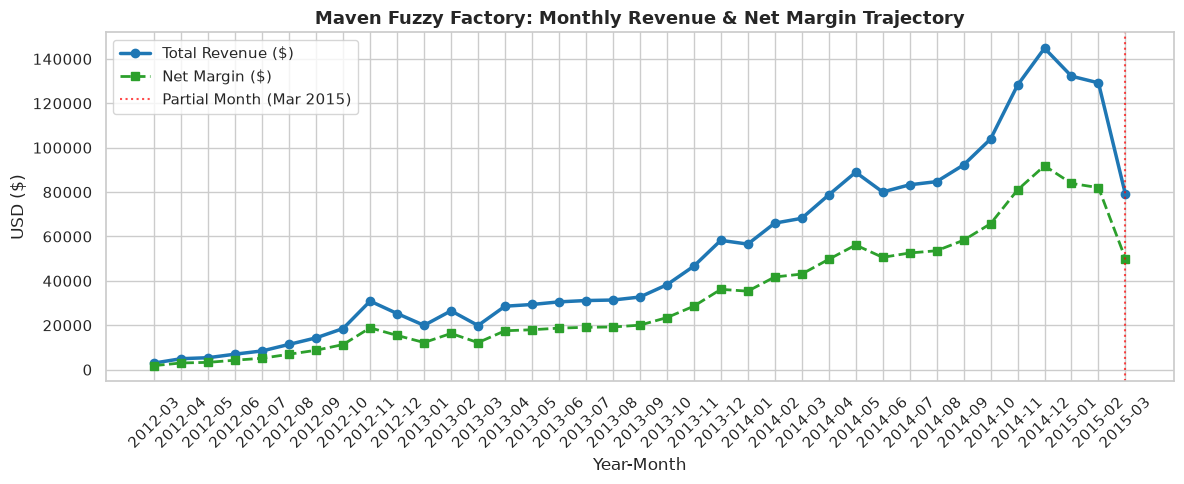

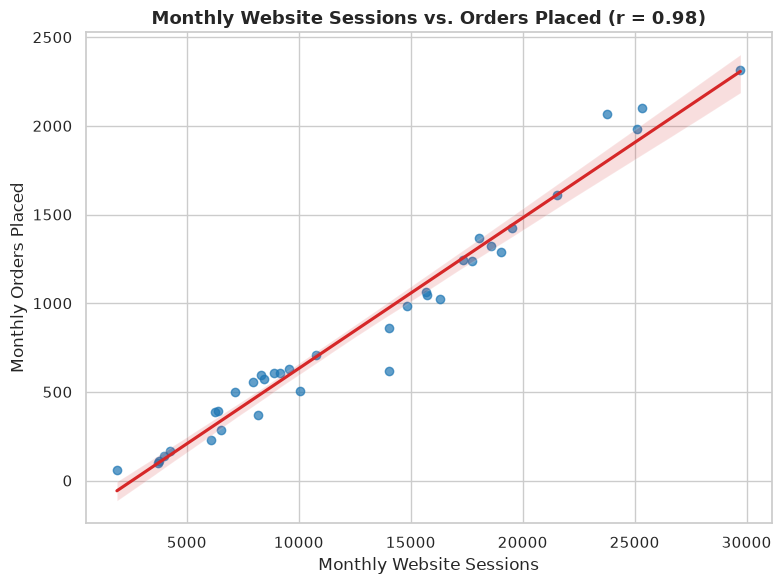

In [20]:
sns.set_theme(style="whitegrid")

# Chart 1: Monthly Revenue & Net Margin Over Time
fig, ax = plt.subplots(figsize=(12, 5))
x_labels = monthly_perf.index.astype(str)
ax.plot(x_labels, monthly_perf['total_revenue'], marker='o', linewidth=2.5, label='Total Revenue ($)', color='#1f77b4')
ax.plot(x_labels, monthly_perf['net_margin'], marker='s', linewidth=2, linestyle='--', label='Net Margin ($)', color='#2ca02c')
ax.axvline(x=len(x_labels)-1, color='red', linestyle=':', alpha=0.7, label='Partial Month (Mar 2015)')
plt.title('Maven Fuzzy Factory: Monthly Revenue & Net Margin Trajectory', fontsize=13, fontweight='bold')
plt.xlabel('Year-Month')
plt.ylabel('USD ($)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig('Visualisations/01_monthly_revenue_trend.png', dpi=300)
plt.show()

# Chart 2: Website Sessions vs. Monthly Orders (Scatter + Regression Line)
plt.figure(figsize=(8, 6))
sns.regplot(data=full_months, x='sessions', y='orders_count', scatter_kws={'alpha': 0.7, 'color': '#1f77b4'}, line_kws={'color': '#d62728'})
plt.title(f'Monthly Website Sessions vs. Orders Placed (r = {r_val:.2f})', fontsize=13, fontweight='bold')
plt.xlabel('Monthly Website Sessions')
plt.ylabel('Monthly Orders Placed')
plt.tight_layout()
plt.savefig('Visualisations/02_sessions_vs_orders_regression.png', dpi=300)
plt.show()

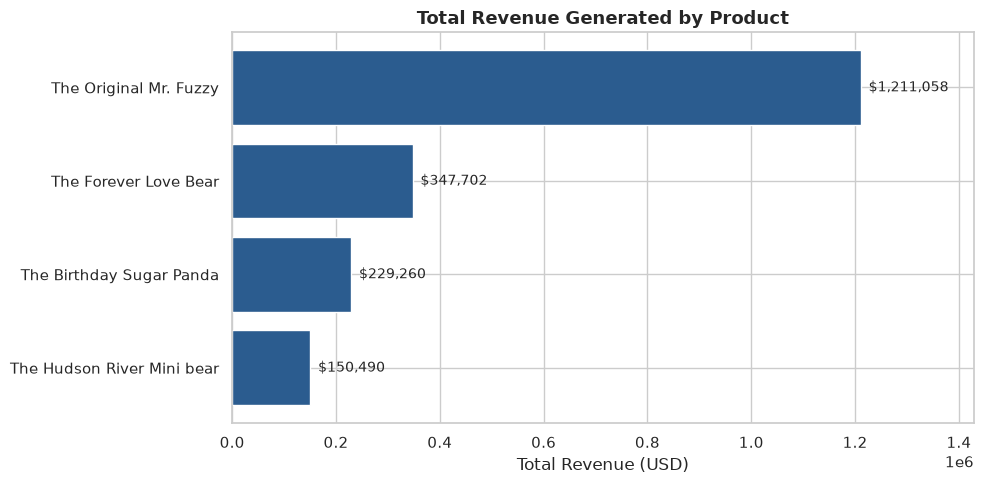

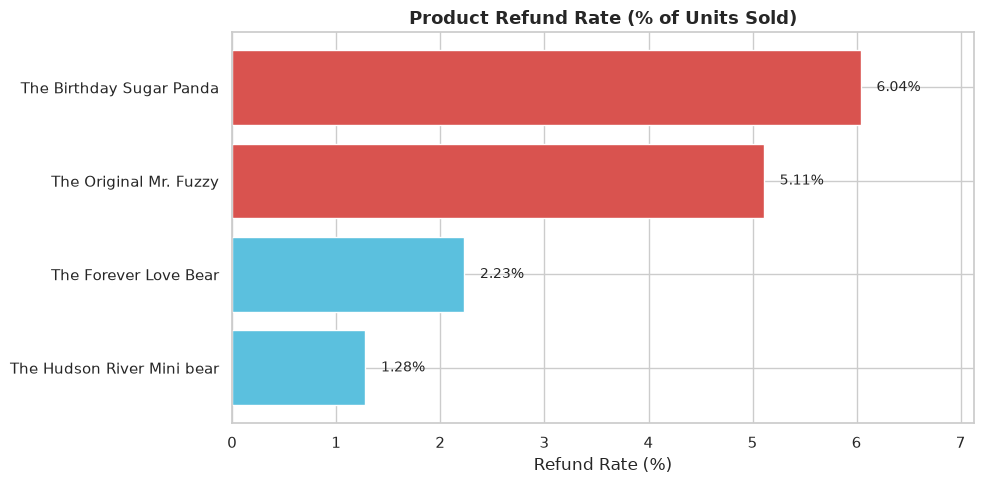

In [21]:
# Chart 3: Total Revenue & Units Sold by Product
prod_sorted = prod_perf.sort_values(by='total_revenue', ascending=True)
plt.figure(figsize=(10, 5))
bars = plt.barh(prod_sorted.index, prod_sorted['total_revenue'], color='#2b5c8f')
plt.title('Total Revenue Generated by Product', fontsize=13, fontweight='bold')
plt.xlabel('Total Revenue (USD)')
for bar in bars:
    width = bar.get_width()
    plt.text(width + 15000, bar.get_y() + bar.get_height()/2, f'${width:,.0f}', va='center', fontsize=10)
plt.xlim(0, prod_sorted['total_revenue'].max() * 1.18)
plt.tight_layout()
plt.savefig('Visualisations/03_product_revenue.png', dpi=300)
plt.show()

# Chart 4: Refund Rate (%) by Product
ref_sorted = refund_summary.sort_values(by='refund_rate_%', ascending=True)
plt.figure(figsize=(10, 5))
colors = ['#d9534f' if rate > 5 else '#5bc0de' for rate in ref_sorted['refund_rate_%']]
bars = plt.barh(ref_sorted.index, ref_sorted['refund_rate_%'], color=colors)
plt.title('Product Refund Rate (% of Units Sold)', fontsize=13, fontweight='bold')
plt.xlabel('Refund Rate (%)')
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.15, bar.get_y() + bar.get_height()/2, f'{width:.2f}%', va='center', fontsize=10)
plt.xlim(0, ref_sorted['refund_rate_%'].max() * 1.18)
plt.tight_layout()
plt.savefig('Visualisations/04_product_refund_rates.png', dpi=300)
plt.show()

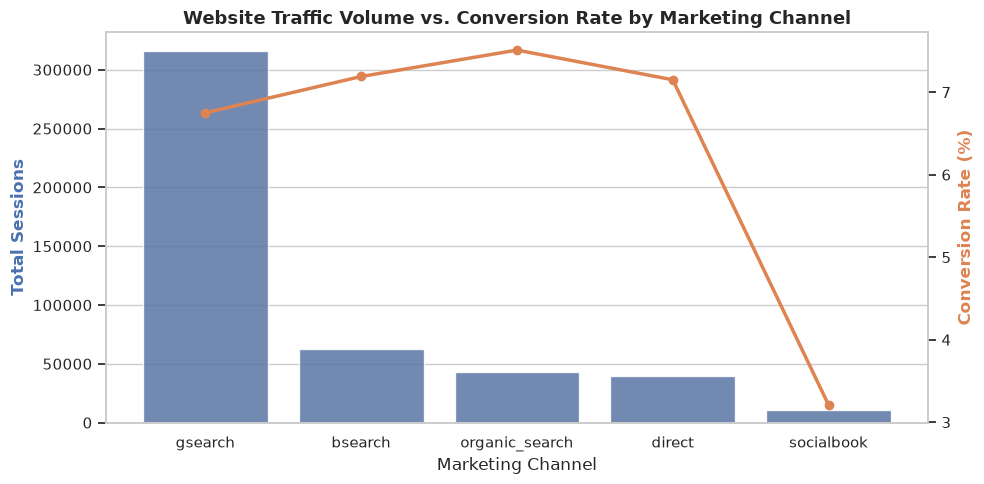

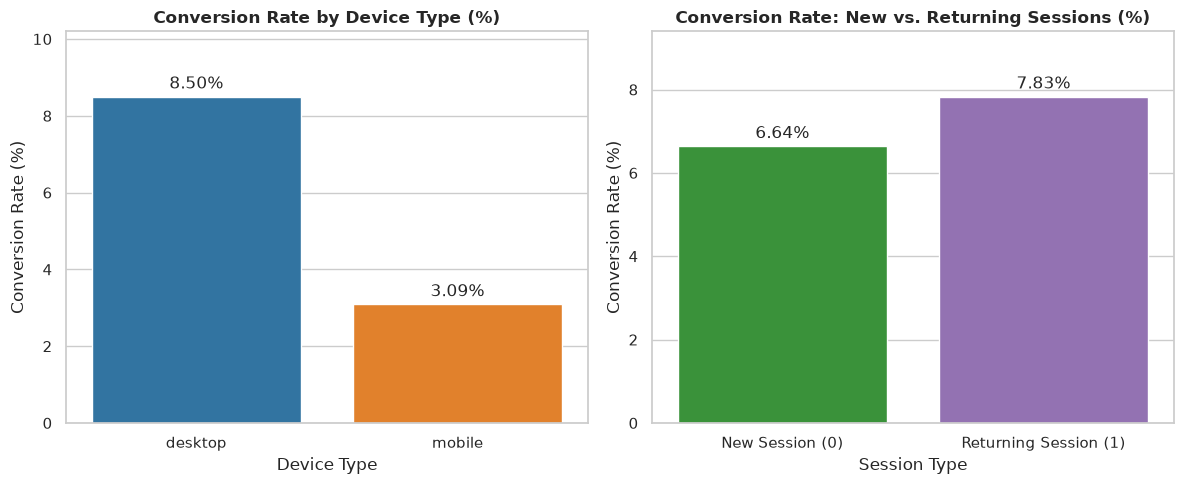

In [22]:
# Chart 5: Website Sessions & Conversion Rate by Marketing Channel
ch_sorted = channel_summary.sort_values(by='sessions', ascending=False)
fig, ax1 = plt.subplots(figsize=(10, 5))
sns.barplot(x=ch_sorted.index, y=ch_sorted['sessions'], ax=ax1, color='#4c72b0', alpha=0.85)
ax1.set_ylabel('Total Sessions', color='#4c72b0', fontweight='bold')
ax1.set_xlabel('Marketing Channel')

ax2 = ax1.twinx()
ax2.plot(ch_sorted.index, ch_sorted['conv_rate_pct'], color='#dd8452', marker='o', linewidth=2.5, label='Conversion Rate (%)')
ax2.set_ylabel('Conversion Rate (%)', color='#dd8452', fontweight='bold')
ax2.grid(False)
plt.title('Website Traffic Volume vs. Conversion Rate by Marketing Channel', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('Visualisations/05_marketing_channel_performance.png', dpi=300)
plt.show()

# Chart 6: Conversion Rate Comparison — Device Type & New vs. Returning Sessions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(x=device_summary.index, y=device_summary['conv_rate_pct'], ax=axes[0], palette=['#1f77b4', '#ff7f0e'], hue=device_summary.index, legend=False)
axes[0].set_title('Conversion Rate by Device Type (%)', fontweight='bold')
axes[0].set_ylabel('Conversion Rate (%)')
axes[0].set_xlabel('Device Type')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f%%', padding=3)
axes[0].set_ylim(0, device_summary['conv_rate_pct'].max() * 1.2)

sns.barplot(x=repeat_summary.index, y=repeat_summary['conv_rate_pct'], ax=axes[1], palette=['#2ca02c', '#9467bd'], hue=repeat_summary.index, legend=False)
axes[1].set_title('Conversion Rate: New vs. Returning Sessions (%)', fontweight='bold')
axes[1].set_ylabel('Conversion Rate (%)')
axes[1].set_xlabel('Session Type')
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f%%', padding=3)
axes[1].set_ylim(0, repeat_summary['conv_rate_pct'].max() * 1.2)

plt.tight_layout()
plt.savefig('Visualisations/06_device_and_repeat_conversion.png', dpi=300)
plt.show()